#FMA Small Analysis
**Daniel Bruning - 10/26/2026**



## Imports

In [79]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import t, ttest_rel

RESULTS_DIR = Path("results/fma_small")

architectures = sorted(
    [
        p.name
        for p in RESULTS_DIR.iterdir()
        if p.is_dir()
    ]
)

GENRES = [
    "electronic",
    "experimental",
    "folk",
    "hip-hop",
    "instrumental",
    "international",
    "pop",
    "rock"
]

## Helper functions

In [80]:
def display_table(df, decimals=4):
    display(
        df.style
          .hide(axis="index")
          .format(precision=decimals)
    )

# 1. Experimental Artifacts and Data Assembly

## Inventory Dataframe

This dataframe inventories the experimental artifacts generated for each architecture, including duration results, genre results, training histories, metadata files, and confusion matrices. It provides a reproducibility check and helps verify all expected outputs were successfully generated prior to analysis.

In [81]:
inventory_records = []

for model in architectures:
    model_path = RESULTS_DIR / model

    inventory_records.append({
        "model": model,
        "duration_results": len(
            list(
                (model_path / "duration_results").glob("*")
            )
        ),
        "genre_results": len(
            list(
                (model_path / "genre_results").glob("*")
            )
        ),
        "histories": len(
            list(
                (model_path / "histories").glob("*")
            )
        ),
        "metadata": len(
            list(
                (model_path / "metadata").glob("*")
            )
        ),
        "confusion_matrices": len(
            list(
                (model_path / "confusion_matrices").glob("*")
            )
        )
    })

artifact_inventory_df = pd.DataFrame(inventory_records)

# display_table(artifact_inventory_df)

## Metadata Dataframe

This dataframe contains architecture-level metadata and training configuration information including parameter counts, input dimensions, and dataset characteristics. It serves as reference for model specifications throughout the analysis.


In [82]:
metadata_frames = []

for model in architectures:

    metadata_files = list(
        (
            RESULTS_DIR
            / model
            / "metadata"
        ).glob("*.csv")
    )

    for file in metadata_files:
        metadata_frames.append(
            pd.read_csv(file)
        )

model_metadata_df = pd.concat(
    metadata_frames,
    ignore_index=True
)
display_table(model_metadata_df)

model,model_category,pretrained,parameter_count,input_height,input_width,channels,num_classes,learning_rate
cnn,scratch_cnn,False,129224,128,128,3,8,0.0010
crnn,temporal_model,False,345096,128,128,3,8,0.0001
mobilenetv2,pretrained_cnn,True,2587976,224,224,3,8,0.0001
vit,vision_transformer,True,1420680,224,224,3,8,0.0001


## Run Metrics Dataframe

This dataframe consolidates run-level experimental results across architectures, durations, and random seeds. It includes training, validation, and test metrics as well as engineered features used throughout the performance, efficiency, and generalization analyses.


In [83]:
run_frames = []

for model in architectures:

    summary_file = (
        RESULTS_DIR
        / model
        / "duration_results"
        / f"{model}_experiment_summary_all.csv"
    )

    if summary_file.exists():
        run_frames.append(
            pd.read_csv(summary_file)
        )

run_summaries_df = pd.concat(
    run_frames,
    ignore_index=True
)

run_summaries_df["duration_seconds"] = (
    run_summaries_df["duration"]
    .str.replace("s", "", regex=False)
    .astype(int)
)


run_summaries_df["params_million"] = (
    run_summaries_df["parameter_count"] / 1_000_000
)

run_summaries_df["accuracy_per_million_params"] = (
    run_summaries_df["test_accuracy"]
    /
    run_summaries_df["params_million"]
)

run_summaries_df["convergence_speed"] = (
    run_summaries_df["best_epoch"]
    /
    run_summaries_df["epochs_completed"]
)

run_summaries_df["abs_generalization_gap"] = (
    run_summaries_df["generalization_gap"].abs()
)
# display_table(run_summaries_df)

## Confusion Matrix Dataframe

This dataframe converts saved confusion matrices into a long-format representation suitable for aggregation and error analysis. Each observation represents the number of samples assigned from one genre to another for a specific architecture, duration, and seed.



In [84]:
confusion_records = []

for model in architectures:

    matrix_dir = (
        RESULTS_DIR
        / model
        / "confusion_matrices"
    )

    for matrix_file in matrix_dir.glob("*.npy"):

        if matrix_file.name.startswith("._"):
            continue

        try:
            matrix = np.load(matrix_file)
        except Exception as e:
            print(
                f"Skipping {matrix_file.name}: {e}"
            )
            continue

        match = re.search(
            r"confusion_matrix_(\d+)s_seed_(\d+)",
            matrix_file.name
        )

        if match is None:
            continue

        duration = int(match.group(1))
        seed = int(match.group(2))

        for i, actual in enumerate(GENRES):
            for j, predicted in enumerate(GENRES):

                confusion_records.append({
                    "model": model,
                    "duration": duration,
                    "seed": seed,
                    "actual": actual,
                    "predicted": predicted,
                    "count": matrix[i, j]
                })

confusion_matrix_long_df = pd.DataFrame(
    confusion_records
)

# confusion_matrix_long_df

## Genre Duration Dataframe

This dataframe contains genre-specific recall values across architectures and audio durations. It serves as the source for evaluating how additional clip length affects classification performance for individual genres.


In [85]:
total_by_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

correct_by_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        == confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "duration", "actual"]
    )["count"]
    .sum()
)

genre_duration_recall_df = (
    (correct_by_genre / total_by_genre)
    .reset_index()
)

genre_duration_recall_df.columns = [
    "model",
    "duration",
    "genre",
    "recall"
]

genre_duration_recall_df = (
    genre_duration_recall_df
    .sort_values(
        ["model", "duration", "genre"]
    )
    .reset_index(drop=True)
)

# genre_duration_recall_df.head()

## Genre Recall by Model Dataframe

This dataframe summarizes mean recall performance for each genre across architectures. It highlights architecture-specific strengths and weaknesses and supports comparisons of genre recognition capability.

In [86]:
total_by_model_genre = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

correct_by_model_genre = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        ["model", "actual"]
    )["count"]
    .sum()
)

genre_recall_by_model_df = (
    (
        correct_by_model_genre
        /
        total_by_model_genre
    )
    .reset_index()
)

genre_recall_by_model_df.columns = [
    "model",
    "genre",
    "recall"
]

# display_table(genre_recall_by_model_df)

## Genre Confusion Dataframe

This dataframe aggregates confusion matrix observations to quantify systematic genre misclassifications. It serves as the primary source for confusion analysis and error-pattern identification.

In [87]:
genre_confusion_summary_df = (
    confusion_matrix_long_df
    .groupby(
        ["model", "actual", "predicted"]
    )["count"]
    .sum()
    .reset_index()
)

genre_confusion_summary_df["actual_total"] = (
    genre_confusion_summary_df
    .groupby(
        ["model", "actual"]
    )["count"]
    .transform("sum")
)

genre_confusion_summary_df[
    "confusion_rate"
] = (
    genre_confusion_summary_df["count"]
    /
    genre_confusion_summary_df["actual_total"]
)

# genre_confusion_summary_df.head()

## Duration Improvement Dataframe

This dataframe captures paired performance changes between 1-second and 30-second excerpts for each architecture and random seed. These observations support duration-effect analyses, significance testing, and effect-size estimation.


In [88]:
metric_cols = [
    "test_accuracy",
    "test_f1",
    "test_precision",
    "test_recall"
]

duration_improvement_records = []

for (model, seed), group in (
    run_summaries_df.groupby(
        ["model", "seed"]
    )
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    record = {
        "model": model,
        "seed": seed,
    }

    for metric in metric_cols:

        base = one_sec.iloc[0][metric]
        final = thirty_sec.iloc[0][metric]

        record[f"{metric}_1s"] = base
        record[f"{metric}_30s"] = final
        record[f"{metric}_gain"] = final - base

    duration_improvement_records.append(record)

duration_improvement_df = pd.DataFrame(
    duration_improvement_records
)

# duration_improvement_df.head()

## Duration Performance

This dataframe summarizes classification performance across audio durations regardless of architecture. It directly supports the central research question regarding the effect of clip length on music genre recognition.

In [89]:
duration_performance_df = (
    run_summaries_df
    .groupby("duration_seconds")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_f1=("test_f1", "mean"),
        std_f1=("test_f1", "std"),

        mean_precision=("test_precision", "mean"),
        mean_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        n_runs=("test_accuracy", "count")
    )
    .reset_index()
)

duration_performance_df["sem_accuracy"] = (
    duration_performance_df["std_accuracy"]
    / np.sqrt(duration_performance_df["n_runs"])
)

duration_performance_df["accuracy_ci95"] = (
    1.96
    * duration_performance_df["sem_accuracy"]
)

duration_performance_df["accuracy_ci95_lower"] = (
    duration_performance_df["mean_accuracy"]
    - duration_performance_df["accuracy_ci95"]
)

duration_performance_df["accuracy_ci95_upper"] = (
    duration_performance_df["mean_accuracy"]
    + duration_performance_df["accuracy_ci95"]
)

duration_performance_df = (
    duration_performance_df
    .sort_values("duration_seconds")
    .reset_index(drop=True)
)

# duration_performance_df

## Duration Gain Summary Dataframe

This dataframe summarizes genre-level recall improvements associated with increased audio duration. Mean gains and confidence intervals are aggregated across experimental repetitions to quantify the magnitude and uncertainty of duration effects.



In [90]:
# --------------------------------------------------
# Seed-level genre recall
# --------------------------------------------------

total = (
    confusion_matrix_long_df
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

correct = (
    confusion_matrix_long_df[
        confusion_matrix_long_df["actual"]
        ==
        confusion_matrix_long_df["predicted"]
    ]
    .groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )["count"]
    .sum()
)

seed_recall = (
    (
        correct
        /
        total
    )
    .reset_index()
)

seed_recall.columns = [
    "model",
    "seed",
    "duration",
    "genre",
    "recall"
]

# --------------------------------------------------
# Duration gain per seed
# --------------------------------------------------

gain_records = []

for (model, genre, seed), group in (
    seed_recall.groupby(
        [
            "model",
            "genre",
            "seed"
        ]
    )
):

    group = group.sort_values(
        "duration"
    )

    try:

        recall_1 = (
            group.loc[
                group["duration"] == 1,
                "recall"
            ]
            .iloc[0]
        )

        recall_30 = (
            group.loc[
                group["duration"] == 30,
                "recall"
            ]
            .iloc[0]
        )

        gain_records.append({
            "model": model,
            "genre": genre,
            "seed": seed,
            "duration_gain": (
                recall_30 - recall_1
            )
        })

    except IndexError:
        pass

gain_df = pd.DataFrame(
    gain_records
)

# --------------------------------------------------
# Confidence intervals
# --------------------------------------------------

summary_records = []

for (model, genre), group in (
    gain_df.groupby(
        ["model", "genre"]
    )
):

    n = len(group)

    mean_gain = (
        group["duration_gain"]
        .mean()
    )

    std_gain = (
        group["duration_gain"]
        .std(ddof=1)
    )

    sem = (
        std_gain
        /
        np.sqrt(n)
    )

    ci95 = (
        t.ppf(0.975, df=n - 1)
        * sem
    )

    summary_records.append({
        "model": model,
        "genre": genre,
        "mean_gain": mean_gain,
        "lower_ci": mean_gain - ci95,
        "upper_ci": mean_gain + ci95,
        "n_seeds": n
    })

duration_recall_gain_summary_df = pd.DataFrame(
    summary_records
)

# display_table(duration_recall_gain_summary_df)

### Confidence Interval Methodology

Confidence intervals were computed from paired recall gains between 1-second and 30-second excerpts. For each genre, recall gains were calculated across all architecture-seed combinations. The mean gain and corresponding 95% confidence interval were estimated using t-distribution values. Genres whose 95% confidence intervals for recall gain remained entirely above zero were considered to exhibit a statistically supported positive
duration effect. Essentially, this looks for evidence longer audio clips improved recall beyond what might reasonably occur due to random chance.

In [91]:
duration_pairs = [
    ("1s", "3s"),
    ("3s", "5s"),
    ("5s", "10s"),
    ("10s", "15s"),
    ("15s", "20s"),
    ("20s", "25s"),
    ("25s", "30s")
]

duration_pair_records = []

for model in run_summaries_df["model"].unique():

    model_df = (
        run_summaries_df[
            run_summaries_df["model"] == model
        ]
    )

    pivot = (
        model_df
        .pivot(
            index="seed",
            columns="duration",
            values="test_accuracy"
        )
    )

    for dur_a, dur_b in duration_pairs:

        if (
            dur_a not in pivot.columns
            or
            dur_b not in pivot.columns
        ):
            continue

        acc_a = pivot[dur_a]
        acc_b = pivot[dur_b]

        gains = acc_b - acc_a

        mean_gain = gains.mean()

        std_gain = gains.std(
            ddof=1
        )

        t_stat, p_value = ttest_rel(
            acc_b,
            acc_a
        )

        cohen_d = (
            mean_gain / std_gain
            if std_gain > 0
            else np.nan
        )

        duration_pair_records.append({

            "Architecture":
                model,

            "Comparison":
                f"{dur_a} → {dur_b}",

            "Mean Gain":
                mean_gain,

            "Std Gain":
                std_gain,

            "t Statistic":
                t_stat,

            "p Value":
                p_value,

            "Cohen's d":
                cohen_d,

            "Significant (p < .05)":
                p_value < 0.05
        })

duration_pairwise_df = (
    pd.DataFrame(
        duration_pair_records
    )
)
display_table(duration_pairwise_df)

Architecture,Comparison,Mean Gain,Std Gain,t Statistic,p Value,Cohen's d,Significant (p < .05)
cnn,1s → 3s,0.0381,0.0501,1.6999,0.1644,0.7602,False
cnn,3s → 5s,-0.0214,0.0344,-1.3895,0.2370,-0.6214,False
cnn,5s → 10s,0.0098,0.0606,0.3634,0.7347,0.1625,False
cnn,10s → 15s,0.0269,0.0482,1.2457,0.2808,0.5571,False
cnn,15s → 20s,-0.0265,0.0583,-1.0187,0.3659,-0.4556,False
cnn,20s → 25s,-0.0048,0.0887,-0.1220,0.9088,-0.0546,False
cnn,25s → 30s,-0.0085,0.0728,-0.2614,0.8067,-0.1169,False
crnn,1s → 3s,0.0269,0.0160,3.7677,0.0196,1.6850,True
crnn,3s → 5s,0.0280,0.0218,2.8774,0.0451,1.2868,True
crnn,5s → 10s,0.0077,0.0197,0.8731,0.4319,0.3904,False


## Architecture Performance Dataframe

This dataframe summarizes overall predictive performance for each architecture across all durations and seeds. It provides the primary basis for identifying the strongest overall classifiers in the study.

In [92]:
architecture_performance_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean"
        ),

        parameter_count=(
            "parameter_count",
            "first"
        )
    )
    .reset_index()
)

architecture_performance_df[
    "parameters_million"
] = (
    architecture_performance_df["parameter_count"]
    / 1_000_000
)

architecture_performance_df = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
)

# architecture_performance_df.head()

## Architecture Duration Dataframe

This dataframe summarizes predictive performance for each architecture at each audio duration. It supports analysis of how classification quality changes as additional clip length becomes available.


In [93]:
architecture_duration_summary_df = (
    run_summaries_df
    .groupby(
        ["model", "duration_seconds"]
    )
    .agg(
        mean_accuracy=("test_accuracy", "mean"),
        std_accuracy=("test_accuracy", "std"),

        mean_test_f1=("test_f1", "mean"),
        std_test_f1=("test_f1", "std"),

        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),

        n_runs=("seed", "count")
    )
    .reset_index()
)

architecture_duration_summary_df = (
    architecture_duration_summary_df
    .sort_values(
        ["model", "duration_seconds"]
    )
)

# architecture_duration_summary_df.head()

## Model Efficiency Dataframe

This dataframe evaluates computational efficiency by combining model size, training cost, and predictive performance. It supports comparisons of tradeoffs between accuracy and complexity across architectures.

In [94]:
model_efficiency_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        parameter_count=("parameter_count", "first"),
        params_million=("params_million", "first"),

        mean_accuracy=("test_accuracy", "mean"),
        mean_f1=("test_f1", "mean"),

        mean_training_seconds=(
            "training_seconds",
            "mean"
        ),

        mean_accuracy_per_million=(
            "accuracy_per_million_params",
            "mean"
        )
    )
    .reset_index()
)
# display_table(model_efficiency_df)

## Training Behavior Dataframe

This dataframe characterizes model training dynamics, convergence behavior, and generalization performance. Metrics include training time, convergence speed, generalization gap, and overfitting frequency.

In [95]:
training_behavior_df = (
    run_summaries_df
    .groupby("model")
    .agg(
        mean_best_epoch=("best_epoch", "mean"),
        mean_convergence_speed=("convergence_speed", "mean"),
        mean_training_time=("training_seconds", "mean"),
        mean_accuracy_gain=("accuracy_gain", "mean"),
        mean_generalization_gap=(
            "generalization_gap",
            "mean"
        ),
        mean_abs_gap=(
            "abs_generalization_gap",
            "mean"
        ),
        overfitting_rate=(
            "overfitting_flag",
            "mean"
        )
    )
    .reset_index()
)

# display_table(training_behavior_df)

## Duration Research Dataframe

In [96]:
research_records = []

for model, group in (
    run_summaries_df.groupby("model")
):

    one_sec = group[
        group["duration_seconds"] == 1
    ]

    thirty_sec = group[
        group["duration_seconds"] == 30
    ]

    if one_sec.empty or thirty_sec.empty:
        continue

    mean_acc_1s = one_sec["test_accuracy"].mean()
    mean_acc_30s = thirty_sec["test_accuracy"].mean()

    mean_recall_1s = one_sec["test_recall"].mean()
    mean_recall_30s = thirty_sec["test_recall"].mean()

    gain_row = (
        duration_improvement_df[
            duration_improvement_df["model"]
            == model
        ]
    )

    accuracy_gain_mean = (
        gain_row["test_accuracy_gain"].mean()
    )

    recall_gain_mean = (
        gain_row["test_recall_gain"].mean()
    )

    accuracy_ci = (
        1.96
        * gain_row["test_accuracy_gain"].std(ddof=1)
        / np.sqrt(len(gain_row))
    )

    research_records.append({
        "model": model,

        "mean_accuracy_1s": mean_acc_1s,
        "mean_accuracy_30s": mean_acc_30s,
        "accuracy_gain": accuracy_gain_mean,

        "mean_recall_1s": mean_recall_1s,
        "mean_recall_30s": mean_recall_30s,
        "recall_gain": recall_gain_mean,

        "accuracy_ci_lower":
            accuracy_gain_mean - accuracy_ci,

        "accuracy_ci_upper":
            accuracy_gain_mean + accuracy_ci
    })

duration_research_question_df = pd.DataFrame(
    research_records
)

duration_research_question_df = (
    duration_research_question_df
    .sort_values(
        "accuracy_gain",
        ascending=False
    )
)

display_table(duration_research_question_df)

model,mean_accuracy_1s,mean_accuracy_30s,accuracy_gain,mean_recall_1s,mean_recall_30s,recall_gain,accuracy_ci_lower,accuracy_ci_upper
mobilenetv2,0.4624,0.5205,0.0581,0.4625,0.5207,0.0582,0.0433,0.0729
crnn,0.4082,0.4644,0.0563,0.4082,0.4646,0.0563,0.0363,0.0762
vit,0.3494,0.3669,0.0175,0.3496,0.3671,0.0175,0.0056,0.0295
cnn,0.4130,0.4265,0.0135,0.4131,0.4267,0.0136,-0.0722,0.0992


## Duration Rankings Dataframe

In [97]:
model_duration_rankings_df = (
    architecture_duration_summary_df
    .copy()
)

model_duration_rankings_df["accuracy_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_accuracy"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["f1_rank"] = (
    model_duration_rankings_df
    .groupby("duration_seconds")["mean_test_f1"]
    .rank(
        ascending=False,
        method="dense"
    )
)

model_duration_rankings_df["mean_rank"] = (
    model_duration_rankings_df[
        ["accuracy_rank", "f1_rank"]
    ]
    .mean(axis=1)
)

model_duration_rankings_df = (
    model_duration_rankings_df
    .sort_values(
        ["duration_seconds", "mean_rank"]
    )
    .reset_index(drop=True)
)


## Duration Significance Statistics Dataframe

In [98]:
significance_records = []

for model, group in (
    duration_improvement_df
    .groupby("model")
):

    acc_1s = group["test_accuracy_1s"]
    acc_30s = group["test_accuracy_30s"]

    t_stat, p_value = ttest_rel(
        acc_30s,
        acc_1s
    )

    gains = group["test_accuracy_gain"]

    mean_gain = gains.mean()
    std_gain = gains.std(ddof=1)

    # Cohen's d for paired samples
    cohen_d = (
        mean_gain / std_gain
        if std_gain > 0
        else np.nan
    )

    significance_records.append({
        "Architecture": model,
        "Mean Accuracy Gain": mean_gain,
        "Std Gain": std_gain,
        "t Statistic": t_stat,
        "p Value": p_value,
        "Cohen's d": cohen_d,
        "Significant (p < .05)": (
            p_value < 0.05
        )
    })

duration_significance_table = (
    pd.DataFrame(significance_records)
    .sort_values(
        "Mean Accuracy Gain",
        ascending=False
    )
    .reset_index(drop=True)
)

# display_table(duration_significance_table)

# 2. Experimental Inventory and Metadata

## Table 1. Experimental Artifact Inventory

In [99]:
artifact_inventory_table = (
    artifact_inventory_df
    .sort_values("model")
    .rename(
        columns={
            "model": "Architecture",
            "duration_results": "Duration Results",
            "genre_results": "Genre Results",
            "histories": "Training Histories",
            "metadata": "Metadata Files",
            "confusion_matrices": "Confusion Matrices"
        }
    )
)
display_table(
    artifact_inventory_table
)

Architecture,Duration Results,Genre Results,Training Histories,Metadata Files,Confusion Matrices
cnn,41,0,40,1,40
crnn,41,0,40,1,40
mobilenetv2,41,0,40,1,40
vit,42,0,40,1,40


### Comments


## Table 2. Architecture Metadata

In [100]:
architecture_metadata_table = (
    model_metadata_df[
        [
            "model",
            "model_category",
            "parameter_count",
            "input_height",
            "input_width"
        ]
    ]
    .copy()
)

architecture_metadata_table["parameter_count"] = (
    architecture_metadata_table["parameter_count"]
    .map(lambda x: f"{x:,}")
)

architecture_metadata_table = (
    architecture_metadata_table.rename(
        columns={
            "model": "Architecture",
            "model_category": "Family",
            "parameter_count": "Parameters",
            "input_height": "Height",
            "input_width": "Width"
        }
    )
)
display_table(
    architecture_metadata_table
)

Architecture,Family,Parameters,Height,Width
cnn,scratch_cnn,"129,224",128,128
crnn,temporal_model,"345,096",128,128
mobilenetv2,pretrained_cnn,"2,587,976",224,224
vit,vision_transformer,"1,420,680",224,224


### Comments


# 3. Overall Architecture Performance

## Figure 1. Architecture Accuracy and Generalization Tradeoffs

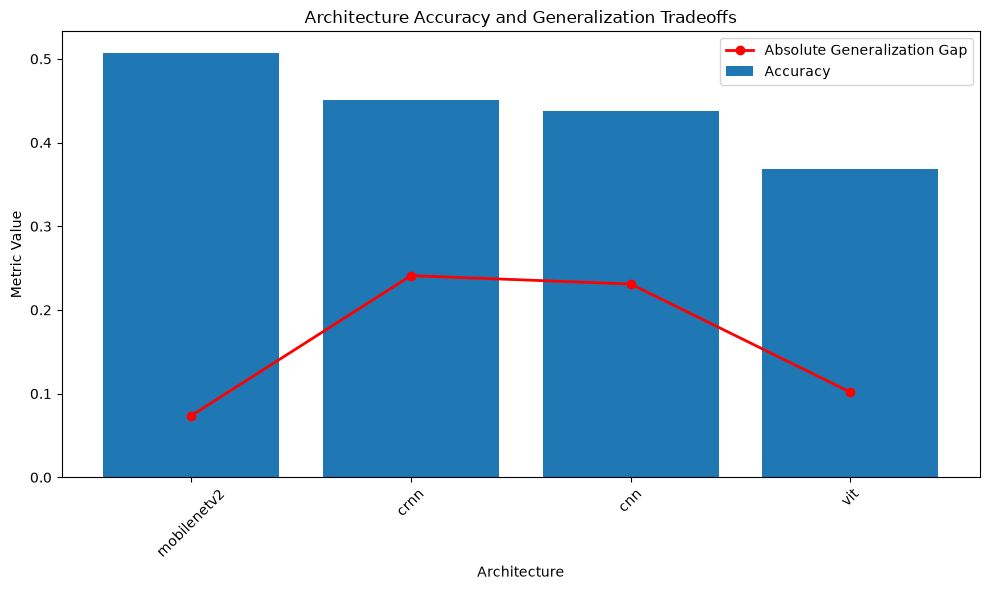

In [101]:
profile_df = (
    training_behavior_df[
        [
            "model",
            "mean_abs_gap"
        ]
    ]
    .merge(
        architecture_performance_df[
            [
                "model",
                "mean_accuracy"
            ]
        ],
        on="model"
    )
    .rename(
        columns={
            "mean_accuracy": "accuracy",
            "mean_abs_gap": "abs_gap"
        }
    )
    .sort_values(
        "accuracy",
        ascending=False
    )
)
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(profile_df))

ax.bar(
    x,
    profile_df["accuracy"],
    label="Accuracy"
)

ax.plot(
    x,
    profile_df["abs_gap"],
    color="red",
    marker="o",
    linewidth=2,
    label="Absolute Generalization Gap"
)

ax.set_xticks(x)
ax.set_xticklabels(
    profile_df["model"],
    rotation=45
)

ax.set_ylabel("Metric Value")
ax.set_xlabel("Architecture")

ax.set_title(
    "Architecture Accuracy and Generalization Tradeoffs"
)

ax.legend()

plt.tight_layout()
plt.show()

### Comments 


## Table 3. Overall Architecture Performance

In [102]:
architecture_performance_table = (
    architecture_performance_df[
        [
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "mean_test_precision",
            "mean_test_recall",
            "parameters_million"
        ]
    ]
    .copy()
)

architecture_performance_table.columns = [
    "Architecture",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "Parameters (M)"
]

architecture_performance_table = (
    architecture_performance_table
    .sort_values(
        "Accuracy",
        ascending=False
    )
)

display_table(
    architecture_performance_table
)

Architecture,Accuracy,F1,Precision,Recall,Parameters (M)
mobilenetv2,0.5075,0.4994,0.5019,0.5077,2.5880
crnn,0.4511,0.4397,0.4503,0.4512,0.3451
cnn,0.4377,0.4154,0.4992,0.4378,0.1292
vit,0.3688,0.3469,0.3588,0.3690,1.4207


### Comments 


## Figure 2. Test Accuracy Distribution by Architecture and Seed

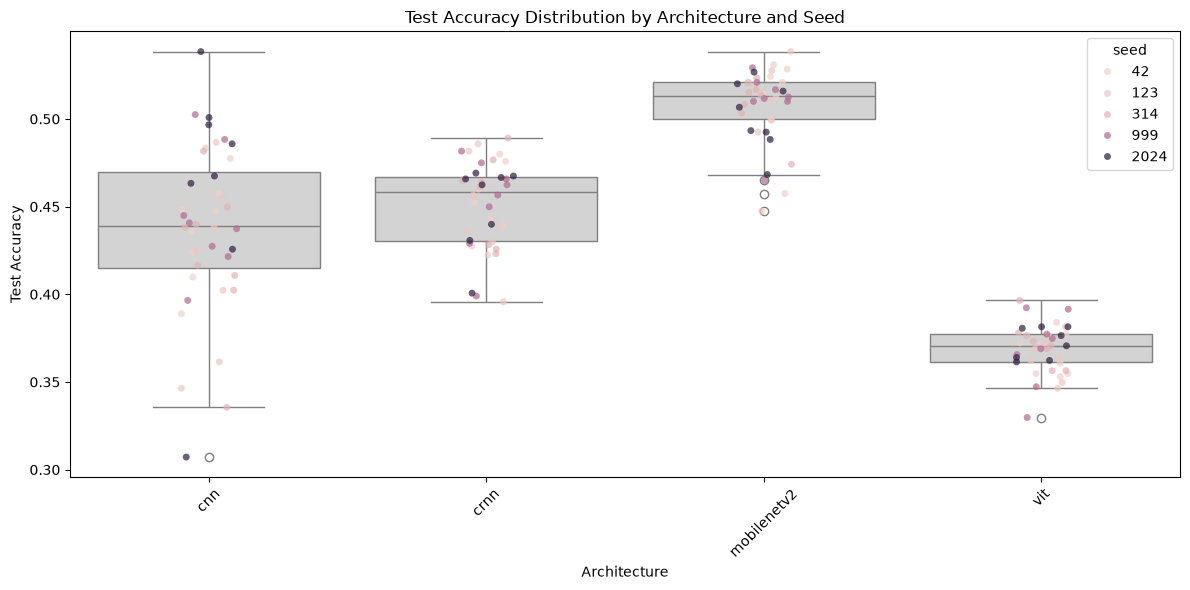

In [103]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    color="lightgray"
)

sns.stripplot(
    data=run_summaries_df,
    x="model",
    y="test_accuracy",
    hue="seed",
    dodge=False,
    alpha=0.7,
    size=5
)

plt.ylabel("Test Accuracy")
plt.xlabel("Architecture")

plt.title(
    "Test Accuracy Distribution by Architecture and Seed"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments 


## Table 4. Model Efficiency Ranking

In [104]:
model_efficiency_table = (
    model_efficiency_df[
        [
            "model",
            "params_million",
            "mean_accuracy",
            "mean_accuracy_per_million",
            "mean_training_seconds"
        ]
    ]
    .copy()
)

model_efficiency_table.columns = [
    "Architecture",
    "Parameters (M)",
    "Accuracy",
    "Accuracy / Million Params",
    "Training Seconds"
]

display_table(
    model_efficiency_table
)

Architecture,Parameters (M),Accuracy,Accuracy / Million Params,Training Seconds
cnn,0.1292,0.4377,3.3869,211.7753
crnn,0.3451,0.4511,1.3071,235.1405
mobilenetv2,2.5880,0.5075,0.1961,291.2290
vit,1.4207,0.3688,0.2596,1016.0493


### Comments


## Figure 3. Generalization Gap by Architecture

Text(0.5, 1.0, 'Generalization Gap by Architecture')

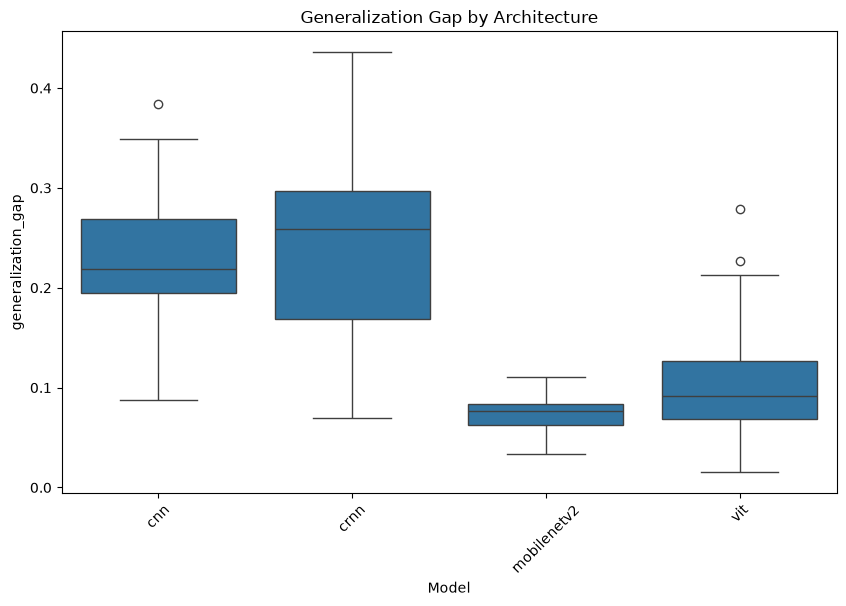

In [105]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="model",
    y="generalization_gap"
)

plt.xlabel("Generalization Gap")
plt.xlabel("Model")

plt.xticks(rotation=45)
plt.title("Generalization Gap by Architecture")

### Comments 


## Table 5. Training Behavior Summary

In [106]:
training_behavior_table = (
    training_behavior_df
    .copy()
)

training_behavior_table.columns = [
    "Architecture",
    "Avg Best Epoch",
    "Convergence Speed",
    "Training Seconds",
    "Training Accuracy Gain",
    "Generalization Gap",
    "Absolute Gap",
    "Overfitting Rate"
]


display_table(
    training_behavior_table
)

Architecture,Avg Best Epoch,Convergence Speed,Training Seconds,Training Accuracy Gain,Generalization Gap,Absolute Gap,Overfitting Rate
cnn,10.4750,0.6519,211.7753,0.3133,0.2310,0.2310,0.7250
crnn,13.5500,0.7124,235.1405,0.3311,0.2410,0.2410,0.6500
mobilenetv2,20.6500,0.8193,291.2290,0.1252,0.0737,0.0737,0.0000
vit,14.0500,0.7254,1016.0493,0.1419,0.1017,0.1017,0.0750


### Comments


## Figure 4. Architecture Efficiency Landscape

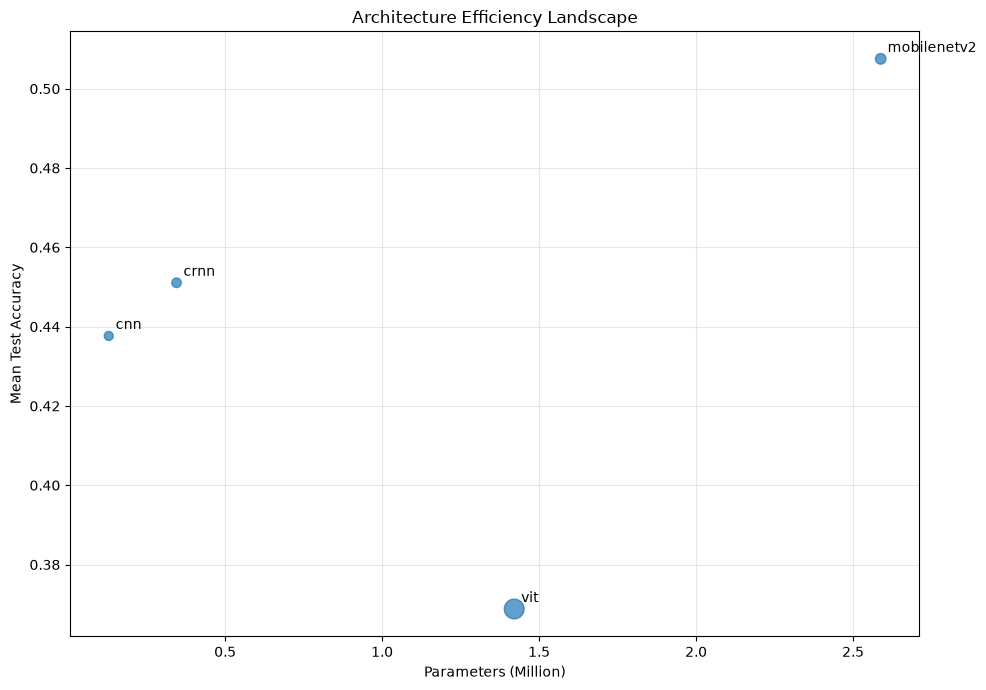

In [107]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    model_efficiency_df["params_million"],
    model_efficiency_df["mean_accuracy"],
    s=model_efficiency_df["mean_training_seconds"] / 5,
    alpha=0.7
)

for _, row in model_efficiency_df.iterrows():
    plt.annotate(
        row["model"],
        (
            row["params_million"],
            row["mean_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Parameters (Million)")
plt.ylabel("Mean Test Accuracy")

plt.title(
    "Architecture Efficiency Landscape"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Comments


# 4. Duration Effects

## Figure 5. Accuracy as a Function of Audio Duration

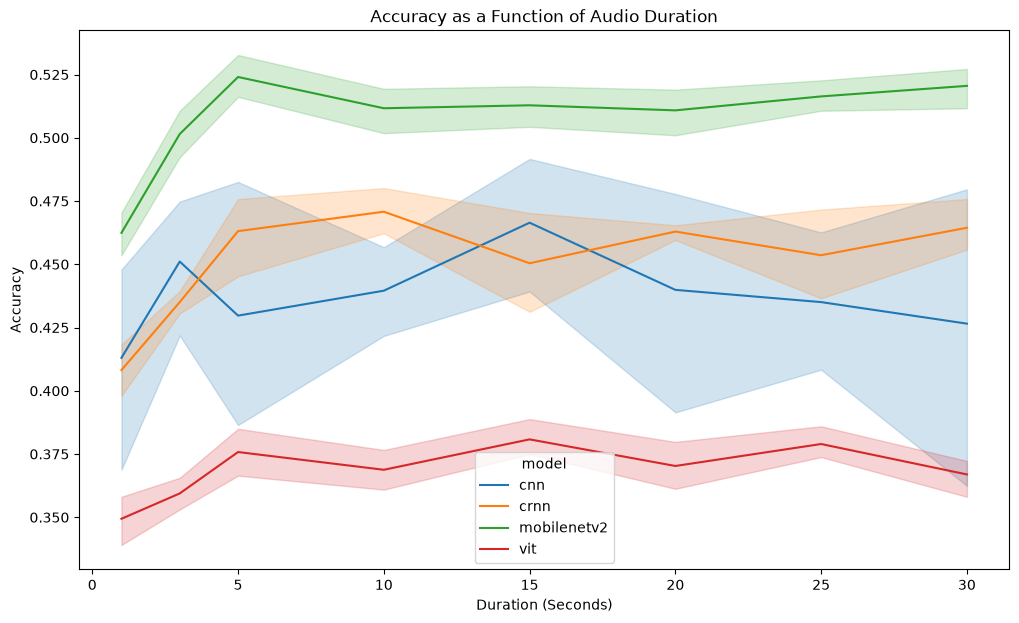

In [108]:
plt.figure(figsize=(12,7))

sns.lineplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy",
    hue="model",
    estimator="mean",
    errorbar=("ci",95)
)

plt.ylabel("Accuracy")
plt.xlabel("Duration (Seconds)")

plt.title(
    "Accuracy as a Function of Audio Duration"
)

plt.show()

### Comments


## Figure 6. Accuracy Gain by Duration Increment

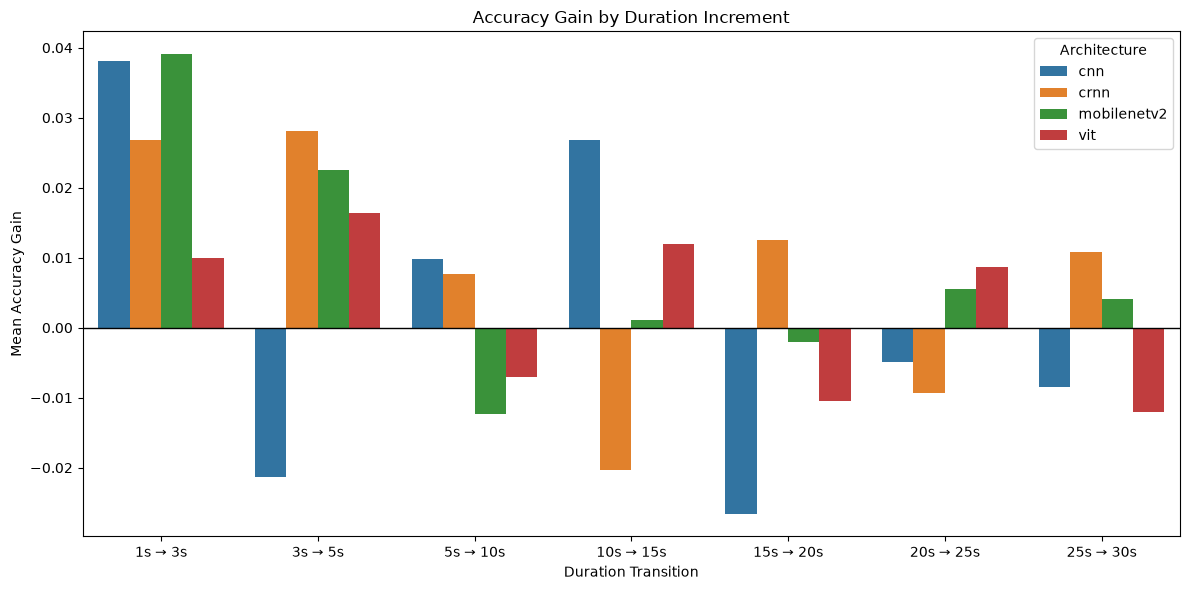

In [109]:
duration_pairwise_df["End Duration"] = (
    duration_pairwise_df["Comparison"]
    .str.extract(
        r"→\s*(\d+)s"
    )
    .astype(int)
)
plt.figure(
    figsize=(12, 6)
)

sns.barplot(
    data=duration_pairwise_df,
    x="Comparison",
    y="Mean Gain",
    hue="Architecture"
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Accuracy Gain by Duration Increment"
)

plt.xlabel(
    "Duration Transition"
)

plt.ylabel(
    "Mean Accuracy Gain"
)

plt.tight_layout()

plt.show()

### Comments


## Table 6. Duration Performance Summary

In [110]:
duration_performance_table = (
    duration_performance_df[
        [
            "duration_seconds",
            "mean_accuracy",
            "mean_f1",
            "mean_precision",
            "mean_recall",
            "accuracy_ci95_lower",
            "accuracy_ci95_upper"
        ]
    ]
    .copy()
)

duration_performance_table.columns = [
    "Duration (s)",
    "Accuracy",
    "F1",
    "Precision",
    "Recall",
    "CI Lower",
    "CI Upper"
]

display_table(
    duration_performance_table
)

Duration (s),Accuracy,F1,Precision,Recall,CI Lower,CI Upper
1,0.4083,0.3940,0.4168,0.4084,0.3874,0.4292
3,0.4368,0.4219,0.4468,0.4369,0.4126,0.4609
5,0.4482,0.4316,0.4609,0.4484,0.4201,0.4763
10,0.4477,0.4323,0.4613,0.4478,0.4235,0.4720
15,0.4526,0.4370,0.4588,0.4528,0.4296,0.4757
20,0.4460,0.4327,0.4559,0.4461,0.4202,0.4718
25,0.4460,0.4292,0.4679,0.4461,0.4223,0.4697
30,0.4446,0.4241,0.4518,0.4448,0.4150,0.4742


### Comments


## Figure 7. Test Accuracy by Audio Duration

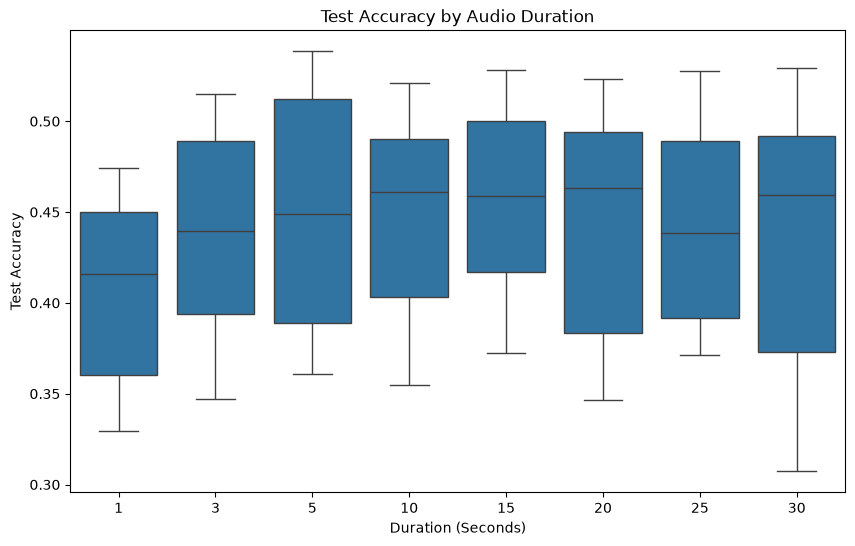

In [111]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=run_summaries_df,
    x="duration_seconds",
    y="test_accuracy"
)

plt.title(
    "Test Accuracy by Audio Duration"
)

plt.xlabel("Duration (Seconds)")
plt.ylabel("Test Accuracy")

plt.show()

### Comments


## Table 7. Duration Rankings

In [112]:
duration_rankings_table = (
    model_duration_rankings_df[
        [
            "duration_seconds",
            "model",
            "mean_accuracy",
            "mean_test_f1",
            "accuracy_rank",
            "f1_rank",
            "mean_rank"
        ]
    ]
    .copy()
)

duration_rankings_table.columns = [
    "Duration (s)",
    "Architecture",
    "Accuracy",
    "F1",
    "Accuracy Rank",
    "F1 Rank",
    "Composite Rank"
]

duration_rankings_table

,Duration (s),Architecture,Accuracy,F1,Accuracy Rank,F1 Rank,Composite Rank
0,1,mobilenetv2,0.462437,0.453413,1.0,1.0,1.0
1,1,cnn,0.413022,0.393520,2.0,3.0,2.5
2,1,crnn,0.408180,0.394233,3.0,2.0,2.5
3,1,vit,0.349416,0.334920,4.0,4.0,4.0
4,3,mobilenetv2,0.501503,0.492338,1.0,1.0,1.0
5,3,cnn,0.451085,0.430750,2.0,2.0,2.0
6,3,crnn,0.435058,0.424261,3.0,3.0,3.0
7,3,vit,0.359432,0.340107,4.0,4.0,4.0
8,5,mobilenetv2,0.524040,0.514878,1.0,1.0,1.0
9,5,crnn,0.463105,0.452175,2.0,2.0,2.0


### Comments


## Table 8. Statistical Significance of Duration Effects

In [113]:
duration_significance_table[
    "Mean Accuracy Gain (%)"
] = (
    duration_significance_table[
        "Mean Accuracy Gain"
    ]
    * 100
)

duration_significance_table = (
    duration_significance_table[
        [
            "Architecture",
            "Mean Accuracy Gain (%)",
            "t Statistic",
            "p Value",
            "Cohen's d",
            "Significant (p < .05)"
        ]
    ]
)

display_table(duration_significance_table)

Architecture,Mean Accuracy Gain (%),t Statistic,p Value,Cohen's d,Significant (p < .05)
mobilenetv2,5.8097,7.7115,0.0015,3.4487,True
crnn,5.6260,5.5187,0.0053,2.4680,True
vit,1.7529,2.8711,0.0454,1.2840,True
cnn,1.3523,0.3093,0.7725,0.1383,False


### Comments


# 5. Genre-Level Analysis

## Figure 8. Genre Sensitivity to Additional Audio Duration

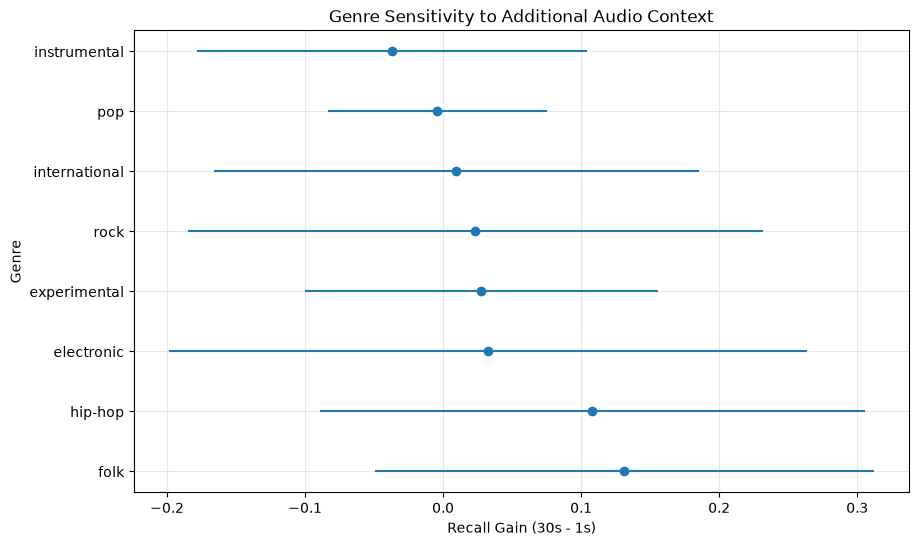

In [114]:
genre_plot = (
    duration_recall_gain_summary_df
    .groupby("genre")
    .agg(
        gain=("mean_gain", "mean"),
        lower=("lower_ci", "mean"),
        upper=("upper_ci", "mean")
    )
    .reset_index()
)

genre_plot = genre_plot.sort_values(
    "gain",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.errorbar(
    x=genre_plot["gain"],
    y=genre_plot["genre"],
    xerr=[
        genre_plot["gain"] - genre_plot["lower"],
        genre_plot["upper"] - genre_plot["gain"]
    ],
    fmt="o"
)

plt.xlabel(
    "Recall Gain (30s - 1s)"
)

plt.ylabel("Genre")

plt.title(
    "Genre Sensitivity to Additional Audio Context"
)

plt.grid(alpha=0.3)

plt.show()

### Comments


## Table 9. Genre Duration Sensitivity and Best Architecture

In [115]:
genre_seed_recall = []

for (
    model,
    seed,
    duration,
    genre
), group in (
    confusion_matrix_long_df.groupby(
        [
            "model",
            "seed",
            "duration",
            "actual"
        ]
    )
):

    total = group["count"].sum()

    correct = (
        group.loc[
            group["actual"]
            == group["predicted"],
            "count"
        ]
        .sum()
    )

    recall = (
        correct / total
        if total > 0
        else np.nan
    )

    genre_seed_recall.append({
        "model": model,
        "seed": seed,
        "duration": duration,
        "genre": genre,
        "recall": recall
    })

genre_seed_recall_df = pd.DataFrame(
    genre_seed_recall
)

# --------------------------------------------------
# Compute genre-level gains and confidence intervals
# --------------------------------------------------

research_records = []

for genre, group in (
    genre_seed_recall_df.groupby("genre")
):

    recall_1s = (
        group[
            group["duration"] == 1
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    recall_30s = (
        group[
            group["duration"] == 30
        ]
        .sort_values(
            ["model", "seed"]
        )["recall"]
    )

    gains = (
        recall_30s.values
        - recall_1s.values
    )

    mean_gain = gains.mean()

    n = len(gains)
    std_gain = gains.std(ddof=1)

    sem = std_gain / np.sqrt(n)

    ci95 = (
        t.ppf(
            0.975,
            df=n - 1
        )
        * sem
    )

    recall_1_mean = recall_1s.mean()
    recall_30_mean = recall_30s.mean()

    relative_gain = (
        100
        * (
            recall_30_mean
            - recall_1_mean
        )
        / recall_1_mean
    )

    ci_lower = mean_gain - ci95
    ci_upper = mean_gain + ci95

    research_records.append({
        "Genre": genre,
        "Recall @ 1s": recall_1_mean,
        "Recall @ 30s": recall_30_mean,
        "Recall Gain": mean_gain,
        "Relative Recall Gain (%)": relative_gain,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Significant": (
            "Yes"
            if ci_lower > 0
            else "No"
        )
    })

gain_stats_df = pd.DataFrame(
    research_records
)

# --------------------------------------------------
# Best architecture for each genre
# --------------------------------------------------

best_architecture_df = (
    genre_recall_by_model_df
    .sort_values(
        "recall",
        ascending=False
    )
    .groupby("genre")
    .first()
    .reset_index()
)

best_architecture_df = (
    best_architecture_df[
        [
            "genre",
            "model",
            "recall"
        ]
    ]
)

best_architecture_df.columns = [
    "Genre",
    "Best Architecture",
    "Best Recall"
]

# --------------------------------------------------
# Final research question table
# --------------------------------------------------

research_question_table = (
    gain_stats_df
    .merge(
        best_architecture_df,
        on="Genre"
    )
    .sort_values(
        "Relative Recall Gain (%)",
        ascending=False
    )
    .reset_index(drop=True)
)

research_question_table = (
    research_question_table[
        [
            "Genre",
            "Recall @ 1s",
            "Recall @ 30s",
            "Recall Gain",
            "Relative Recall Gain (%)",
            "95% CI Lower",
            "95% CI Upper",
            "Significant",
            "Best Architecture",
            "Best Recall"
        ]
    ]
)

display_table(research_question_table)

Genre,Recall @ 1s,Recall @ 30s,Recall Gain,Relative Recall Gain (%),95% CI Lower,95% CI Upper,Significant,Best Architecture,Best Recall
folk,0.4437,0.5750,0.1313,29.6018,0.0486,0.2140,Yes,mobilenetv2,0.6010
hip-hop,0.4765,0.5846,0.1081,22.6761,0.0178,0.1983,Yes,mobilenetv2,0.6394
experimental,0.3093,0.3370,0.0277,8.9440,-0.0238,0.0791,No,mobilenetv2,0.4152
electronic,0.4577,0.4903,0.0326,7.1114,-0.0709,0.1360,No,mobilenetv2,0.5512
rock,0.5450,0.5683,0.0233,4.2813,-0.0637,0.1104,No,crnn,0.5780
international,0.4370,0.4467,0.0097,2.2121,-0.0836,0.1030,No,mobilenetv2,0.5672
pop,0.1217,0.1173,-0.0043,-3.5616,-0.0337,0.0251,No,mobilenetv2,0.1985
instrumental,0.4760,0.4390,-0.0370,-7.7731,-0.1058,0.0318,No,mobilenetv2,0.5192


### Comments


## Figure 9. Genre Recall Profile by Architecture

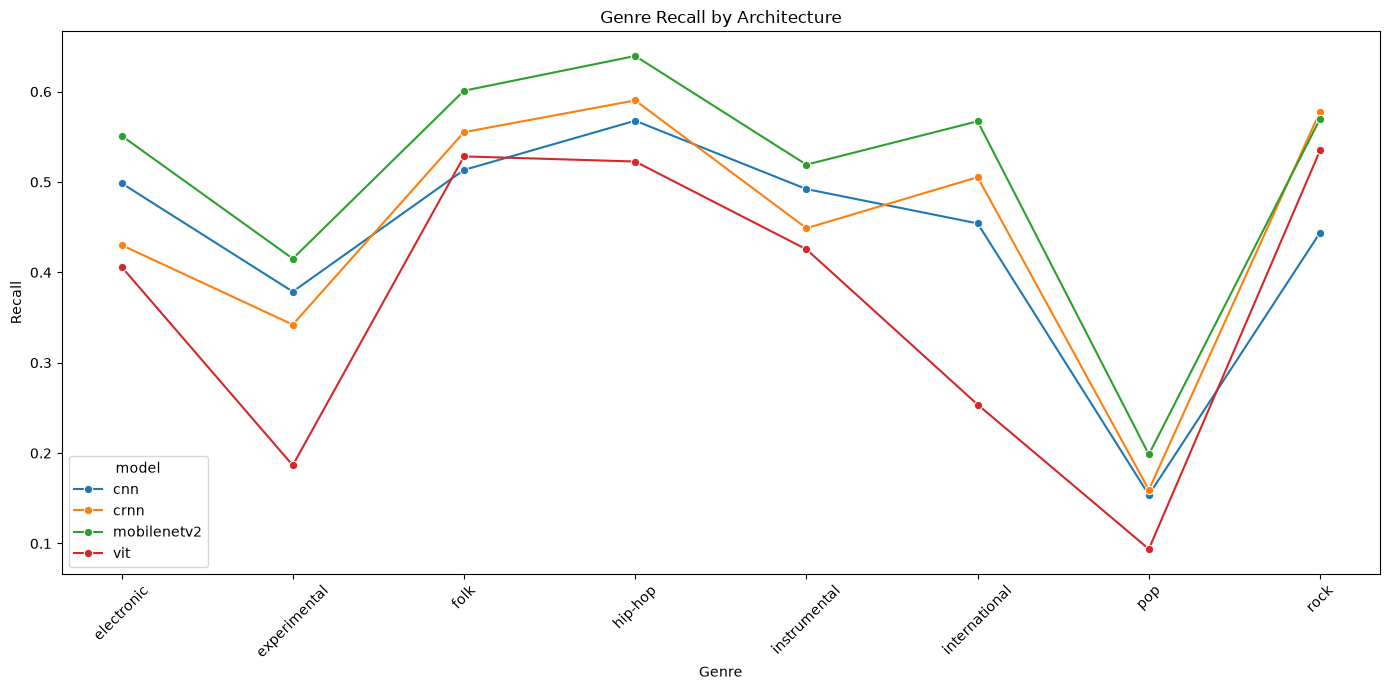

In [116]:
plt.figure(figsize=(14, 7))

genre_means = (
    genre_duration_recall_df
    .groupby(
        ["genre", "model"]
    )["recall"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=genre_means,
    x="genre",
    y="recall",
    hue="model",
    marker="o"
)

plt.title(
    "Genre Recall by Architecture"
)

plt.xlabel("Genre")
plt.ylabel("Recall")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Comments


## Table 10. Genre Recall Summary by Architecture

In [117]:
genre_recall_summary_table = (
    genre_recall_by_model_df
    .pivot(
        index="genre",
        columns="model",
        values="recall"
    )
    .round(3)
)

display_table(genre_recall_summary_table)

cnn,crnn,mobilenetv2,vit
0.4990,0.4300,0.5510,0.4060
0.3790,0.3420,0.4150,0.1860
0.5130,0.5550,0.6010,0.5280
0.5680,0.5900,0.6390,0.5230
0.4920,0.4490,0.5190,0.4260
0.4540,0.5050,0.5670,0.2540
0.1540,0.1590,0.1980,0.0940
0.4440,0.5780,0.5700,0.5350


### Comments


## Table 11. Average Genre Recall Ranking

In [118]:
genre_recall_ranking_table = (
    genre_recall_by_model_df
    .groupby("genre")["recall"]
    .agg(
        mean_recall="mean",
        std_recall="std",
        min_recall="min",
        max_recall="max"
    )
    .reset_index()
    .sort_values(
        "mean_recall",
        ascending=False
    )
)

display_table(
    genre_recall_ranking_table
)

genre,mean_recall,std_recall,min_recall,max_recall
hip-hop,0.5800,0.0486,0.5227,0.6394
folk,0.5495,0.0385,0.5133,0.6010
rock,0.5317,0.0614,0.4440,0.5780
electronic,0.4716,0.0660,0.4062,0.5512
instrumental,0.4714,0.0421,0.4255,0.5192
international,0.4451,0.1357,0.2537,0.5672
experimental,0.3306,0.1006,0.1865,0.4152
pop,0.1514,0.0432,0.0938,0.1985


### Comments


## Table 12. Average Genre Recall Ranking

In [119]:
genre_duration_recall_table = (
    genre_duration_recall_df
    .pivot_table(
        index="genre",
        columns="duration",
        values="recall",
        aggfunc="mean"
    )
    .round(3)
)

display_table(genre_duration_recall_table)

1,3,5,10,15,20,25,30
0.4580,0.4460,0.5670,0.4450,0.4650,0.4490,0.4530,0.4900
0.3090,0.3150,0.3430,0.3580,0.3080,0.3770,0.2970,0.3370
0.4440,0.5460,0.5450,0.5710,0.5820,0.5720,0.5610,0.5750
0.4770,0.6160,0.5680,0.6160,0.6160,0.5790,0.5840,0.5850
0.4760,0.4450,0.4820,0.4760,0.5090,0.4740,0.4700,0.4390
0.4370,0.4610,0.4250,0.4330,0.4680,0.4140,0.4760,0.4470
0.1220,0.1510,0.1410,0.1570,0.1440,0.1860,0.1930,0.1170
0.5450,0.5150,0.5150,0.5270,0.5290,0.5180,0.5360,0.5680


### Comments


## Table 13. Genre Improvement Summary

In [120]:
genre_improvement_table = (
    genre_duration_recall_df
    .groupby(
        ["genre", "duration"]
    )["recall"]
    .mean()
    .reset_index()
    .pivot(
        index="genre",
        columns="duration",
        values="recall"
    )
)

genre_improvement_table["gain_1s_to_30s"] = (
    genre_improvement_table[30]
    - genre_improvement_table[1]
)

genre_improvement_table = (
    genre_improvement_table
    .sort_values(
        "gain_1s_to_30s",
        ascending=False
    )
)

genre_improvement_table

duration,1,3,5,10,15,20,25,30,gain_1s_to_30s
genre,,,,,,,,,
folk,0.443667,0.545667,0.545000,0.571333,0.582000,0.571667,0.561333,0.575000,0.131333
hip-hop,0.476510,0.616443,0.567785,0.616107,0.616107,0.578859,0.583893,0.584564,0.108054
electronic,0.457718,0.445973,0.566779,0.444631,0.465436,0.448993,0.452685,0.490268,0.032550
experimental,0.309333,0.315333,0.343333,0.357667,0.308000,0.377000,0.297333,0.337000,0.027667
rock,0.545000,0.514667,0.515333,0.527333,0.529333,0.518000,0.535667,0.568333,0.023333
international,0.437000,0.461333,0.425000,0.433000,0.468000,0.414000,0.475667,0.446667,0.009667
pop,0.121667,0.150667,0.141333,0.156667,0.144333,0.186333,0.192667,0.117333,-0.004333
instrumental,0.476000,0.445333,0.482333,0.476000,0.509000,0.474000,0.469667,0.439000,-0.037000


### Comments


## Figure 10. Genre Recall by Architecture Across Duration

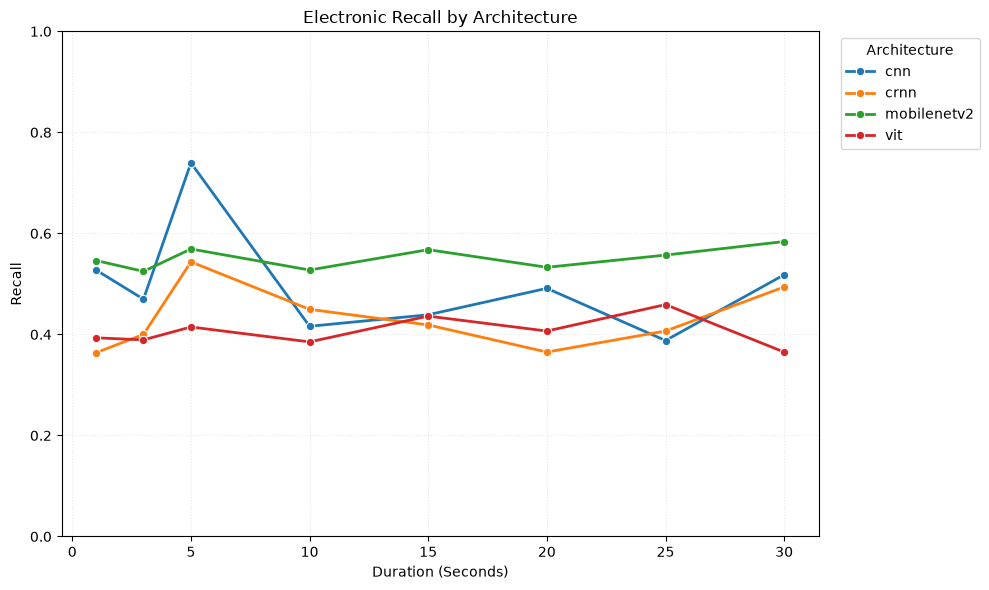

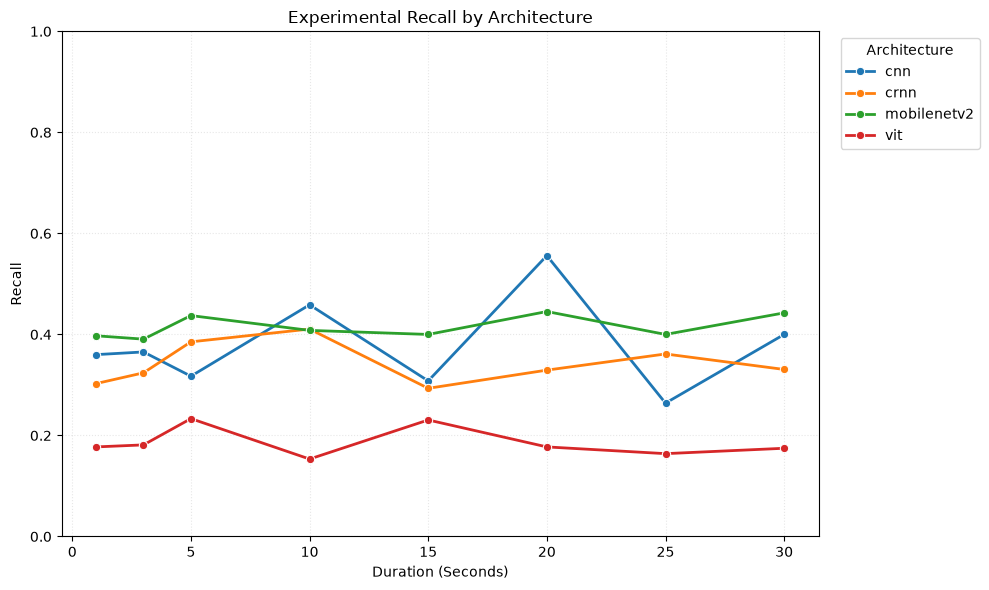

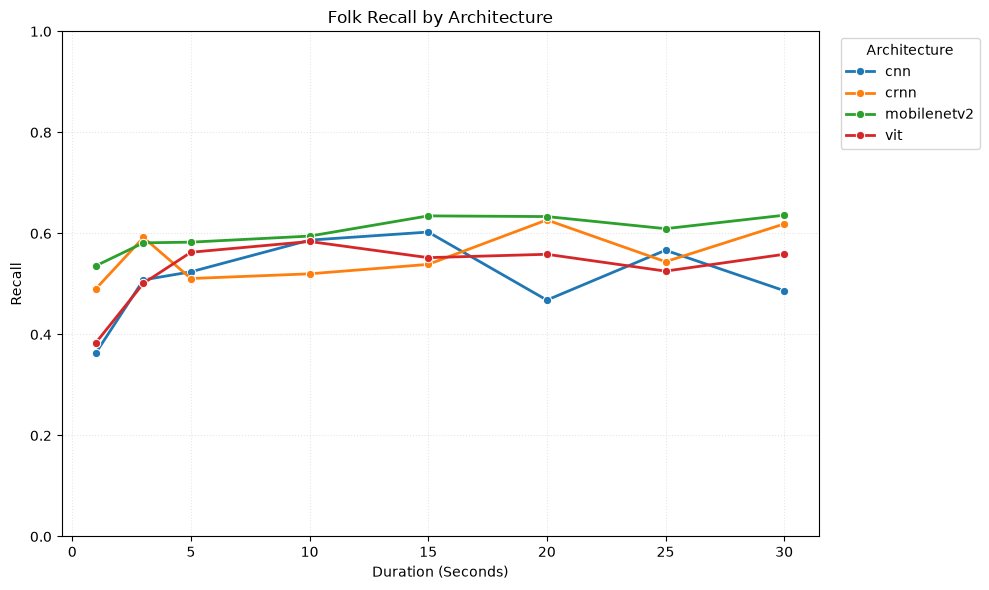

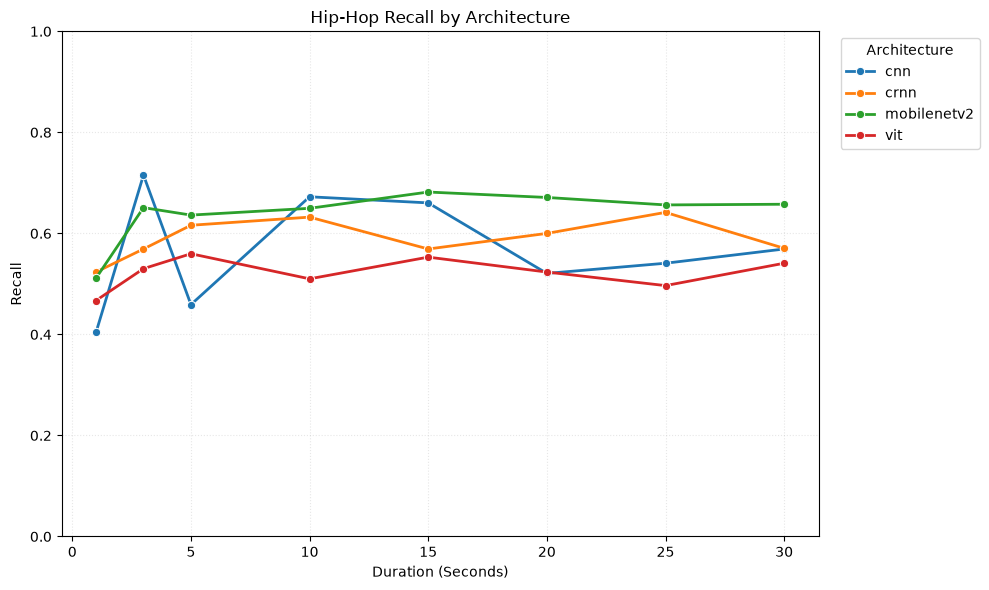

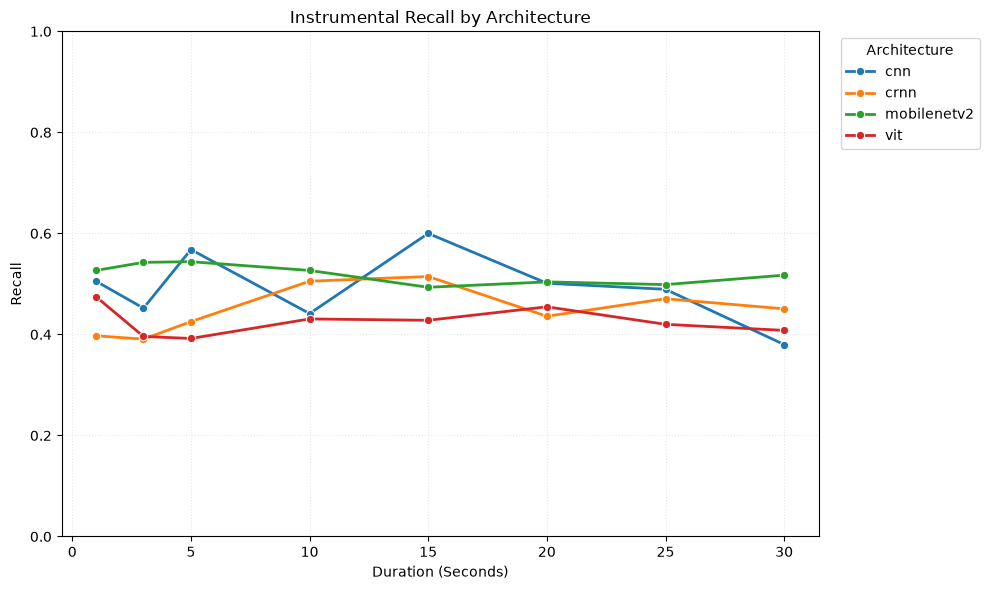

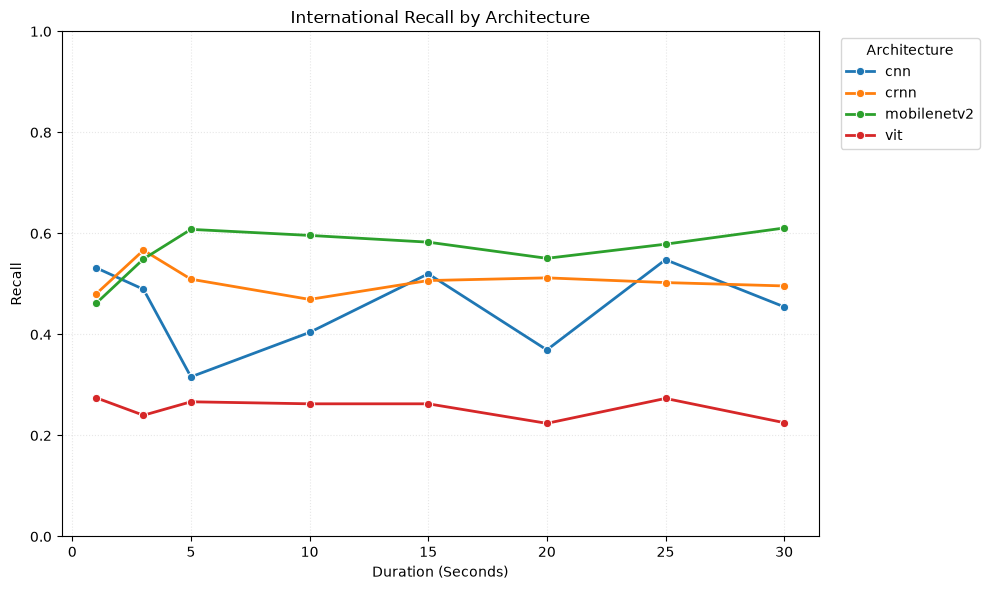

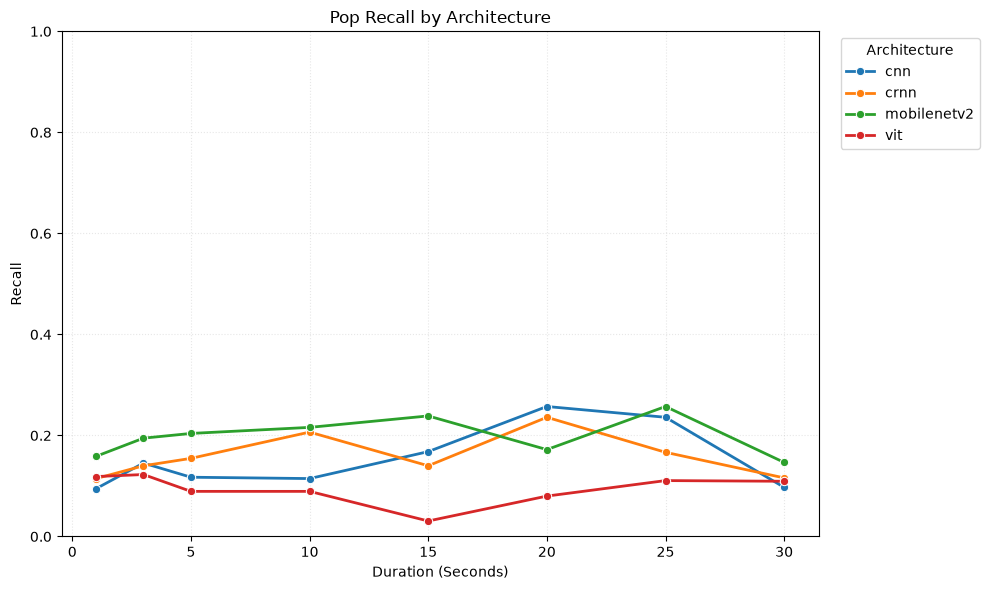

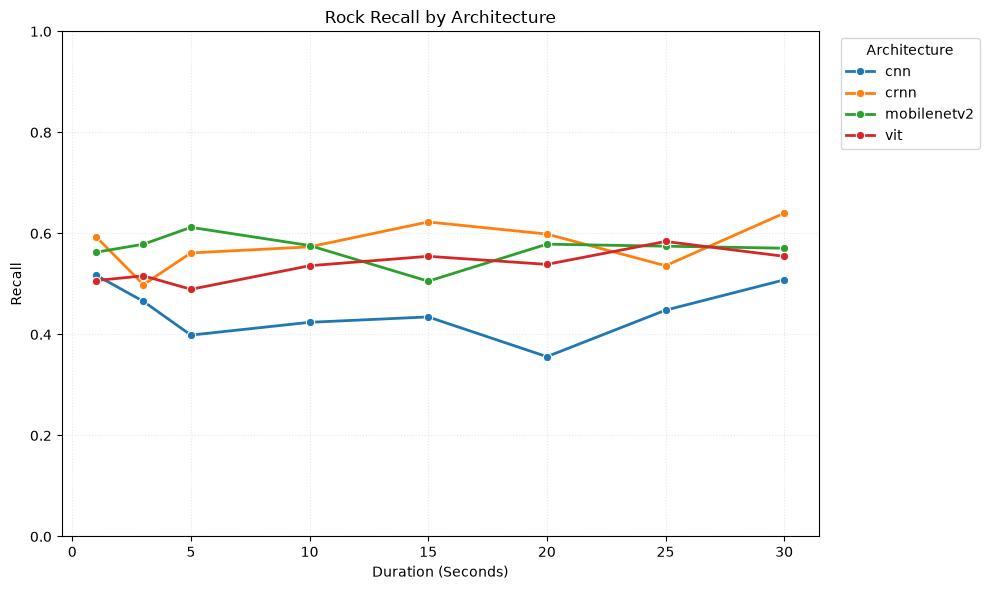

In [121]:
genres = sorted(
    genre_duration_recall_df["genre"].unique()
)

for genre in genres:

    plt.figure(figsize=(10, 6))

    subset = (
        genre_duration_recall_df[
            genre_duration_recall_df["genre"] == genre
        ]
    )

    sns.lineplot(
        data=subset,
        x="duration",
        y="recall",
        hue="model",
        marker="o",
        linewidth=2
    )

    plt.title(
        f"{genre.title()} Recall by Architecture"
    )

    plt.xlabel("Duration (Seconds)")
    plt.ylabel("Recall")

    plt.ylim(0, 1)

    plt.grid(
        alpha=0.3,
        linestyle=":"
    )

    plt.legend(
        title="Architecture",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

### Comments


# 6. Error Analysis

## Table 14. Most Common Genre Confusions

In [122]:
aggregate_genre_confusions_table = (
    genre_confusion_summary_df
    .groupby(
        ["actual", "predicted"]
    )
    .agg(
        total_count=("count", "sum"),
        mean_confusion_rate=("confusion_rate", "mean")
    )
    .reset_index()
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        aggregate_genre_confusions_table["actual"]
        != aggregate_genre_confusions_table["predicted"]
    ]
)

aggregate_genre_confusions_table["confusion_percent"] = (
    aggregate_genre_confusions_table["mean_confusion_rate"]
    * 100
)

aggregate_genre_confusions_table = (
    aggregate_genre_confusions_table[
        [
            "actual",
            "predicted",
            "total_count",
            "confusion_percent"
        ]
    ]
    .sort_values(
        [
            "confusion_percent",
            "total_count"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

aggregate_genre_confusions_table.columns = [
    "Actual Genre",
    "Predicted Genre",
    "Total Misclassifications",
    "Confusion (%)"
]

display_table(
    aggregate_genre_confusions_table.head(20)
)

Actual Genre,Predicted Genre,Total Misclassifications,Confusion (%)
pop,rock,4748,19.7833
hip-hop,electronic,4234,17.7601
electronic,hip-hop,4128,17.3154
pop,folk,3888,16.2000
folk,instrumental,3539,14.7458
experimental,instrumental,3364,14.0167
pop,international,3316,13.8167
instrumental,folk,3199,13.3292
international,hip-hop,3134,13.0583
international,folk,2933,12.2208


### Comments


# Figure 11. Most Common Genre Misclassifications

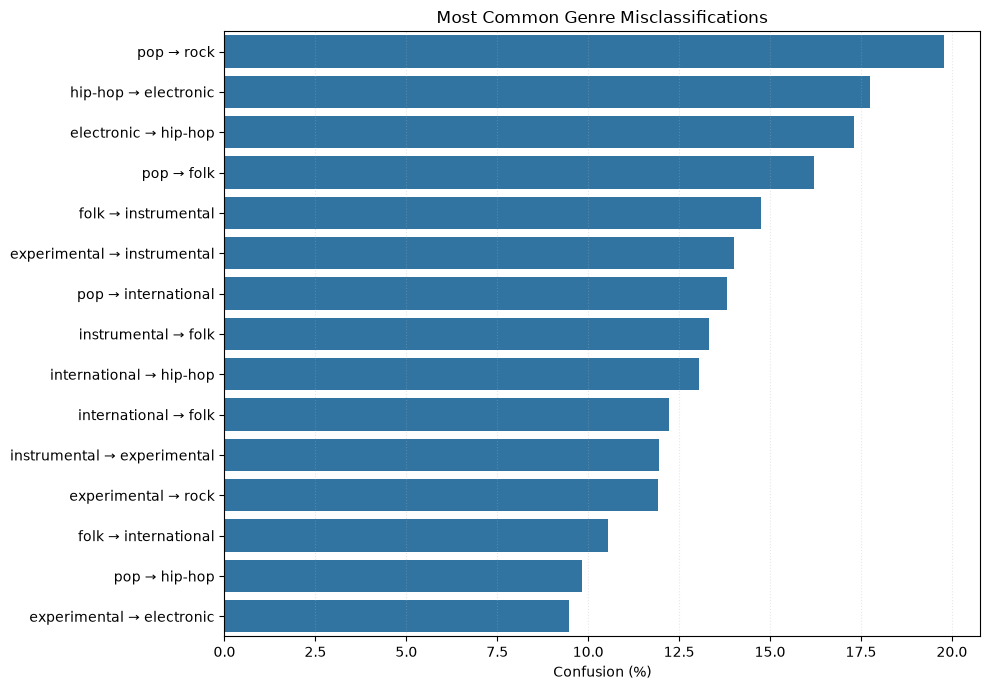

In [123]:
plot_df = (
    aggregate_genre_confusions_table
    .head(15)
    .copy()
)

plot_df["Confusion Pair"] = (
    plot_df["Actual Genre"]
    + " → "
    + plot_df["Predicted Genre"]
)

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(10, 7))

sns.barplot(
    data=plot_df,
    x="Confusion (%)",
    y="Confusion Pair",
    orient="h"
)

plt.title(
    "Most Common Genre Misclassifications"
)

plt.xlabel("Confusion (%)")
plt.ylabel("")

plt.grid(
    axis="x",
    alpha=0.3,
    linestyle=":"
)

plt.tight_layout()
plt.show()

# 7. Leaderboards

## Table 15. Generalization Behavior Summary

In [124]:
generalization_summary_table = (
    training_behavior_df[
        [
            "model",
            "mean_generalization_gap",
            "mean_abs_gap",
            "overfitting_rate"
        ]
    ]
    .copy()
)

generalization_summary_table.columns = [
    "Architecture",
    "Mean Gap",
    "Absolute Gap",
    "Overfitting Rate"
]

generalization_summary_table = (
    generalization_summary_table
    .sort_values(
        "Absolute Gap"
    )
    .reset_index(drop=True)
)

display_table(generalization_summary_table)

Architecture,Mean Gap,Absolute Gap,Overfitting Rate
mobilenetv2,0.0737,0.0737,0.0000
vit,0.1017,0.1017,0.0750
cnn,0.2310,0.2310,0.7250
crnn,0.2410,0.2410,0.6500


### Comments


## Table 16. Architecture Leaderboard

In [125]:
# --------------------------------------------------
# Architecture leaders
# --------------------------------------------------

overall_winner = (
    architecture_performance_df
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

efficiency_winner = (
    model_efficiency_df
    .sort_values(
        "mean_accuracy_per_million",
        ascending=False
    )
    .iloc[0]
)

short_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 1
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

long_duration_winner = (
    architecture_duration_summary_df[
        architecture_duration_summary_df[
            "duration_seconds"
        ] == 30
    ]
    .sort_values(
        "mean_accuracy",
        ascending=False
    )
    .iloc[0]
)

duration_gain_winner = (
    duration_significance_table
    .sort_values(
        "Mean Accuracy Gain (%)",
        ascending=False
    )
    .iloc[0]
)

genre_specialist = (
    genre_recall_by_model_df.loc[
        genre_recall_by_model_df["recall"].idxmax()
    ]
)

# --------------------------------------------------
# Generalization leaders
# --------------------------------------------------

lowest_gap = (
    training_behavior_df
    .sort_values("mean_abs_gap")
    .iloc[0]
)

highest_gap = (
    training_behavior_df
    .sort_values(
        "mean_abs_gap",
        ascending=False
    )
    .iloc[0]
)

lowest_overfit = (
    training_behavior_df
    .sort_values("overfitting_rate")
    .iloc[0]
)

highest_overfit = (
    training_behavior_df
    .sort_values(
        "overfitting_rate",
        ascending=False
    )
    .iloc[0]
)

leaderboard_table = pd.DataFrame([
    {
        "Category": "Overall Accuracy Leader",
        "Architecture": overall_winner["model"],
        "Value": f"{overall_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Most Parameter Efficient",
        "Architecture": efficiency_winner["model"],
        "Value": f"{efficiency_winner['mean_accuracy_per_million']:.3f}"
    },
    {
        "Category": "Best 1-Second Model",
        "Architecture": short_duration_winner["model"],
        "Value": f"{short_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Best 30-Second Model",
        "Architecture": long_duration_winner["model"],
        "Value": f"{long_duration_winner['mean_accuracy']:.3f}"
    },
    {
        "Category": "Largest Duration Gain",
        "Architecture": duration_gain_winner["Architecture"],
        "Value": (
            f"{duration_gain_winner['Mean Accuracy Gain (%)']:.1f}%"
        )
    },
    {
        "Category": "Best Genre Specialist",
        "Architecture": genre_specialist["model"],
        "Value": (
            f"{genre_specialist['genre']} "
            f"({genre_specialist['recall']:.3f})"
        )
    },
    {
        "Category": "Best Generalization",
        "Architecture": lowest_gap["model"],
        "Value": f"{lowest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Lowest Overfitting Rate",
        "Architecture": lowest_overfit["model"],
        "Value": f"{lowest_overfit['overfitting_rate']:.3f}"
    },
    {
        "Category": "Weakest Generalization",
        "Architecture": highest_gap["model"],
        "Value": f"{highest_gap['mean_abs_gap']:.3f}"
    },
    {
        "Category": "Highest Overfitting Rate",
        "Architecture": highest_overfit["model"],
        "Value": f"{highest_overfit['overfitting_rate']:.3f}"
    }
])

display_table(leaderboard_table)

Category,Architecture,Value
Overall Accuracy Leader,mobilenetv2,0.508
Most Parameter Efficient,cnn,3.387
Best 1-Second Model,mobilenetv2,0.462
Best 30-Second Model,mobilenetv2,0.521
Largest Duration Gain,mobilenetv2,5.8%
Best Genre Specialist,mobilenetv2,hip-hop (0.639)
Best Generalization,mobilenetv2,0.074
Lowest Overfitting Rate,mobilenetv2,0.000
Weakest Generalization,crnn,0.241
Highest Overfitting Rate,cnn,0.725


### Comments


# 8. Summary of Findings